In [29]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 01_first_look_at_data

## Exercise 1

In [3]:
df = sns.load_dataset("penguins")

print("First five rows:")
print(df.head())

print("\nShape of the dataset:")
print(df.shape)

print("\nDataset information:")
df.info()

First five rows:
  species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0  Adelie  Torgersen            39.1           18.7              181.0   
1  Adelie  Torgersen            39.5           17.4              186.0   
2  Adelie  Torgersen            40.3           18.0              195.0   
3  Adelie  Torgersen             NaN            NaN                NaN   
4  Adelie  Torgersen            36.7           19.3              193.0   

   body_mass_g     sex  
0       3750.0    Male  
1       3800.0  Female  
2       3250.0  Female  
3          NaN     NaN  
4       3450.0  Female  

Shape of the dataset:
(344, 7)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 

In [5]:
# Number of records and columns
n_records, n_columns = df.shape

print("Data dictionary:")
print(f"1. The dataset contains {n_records} records and {n_columns} columns.")

print("2. Measurement columns: number, orbital_period, mass, distance, year.")
print("   Label column: method.")

print("3. Based on info(), columns with missing data are likely:")
print("   orbital_period, mass, and distance.")
print("   This is because their non-null counts are smaller than the total number of records.")

Data dictionary:
1. The dataset contains 344 records and 7 columns.
2. Measurement columns: number, orbital_period, mass, distance, year.
   Label column: method.
3. Based on info(), columns with missing data are likely:
   orbital_period, mass, and distance.
   This is because their non-null counts are smaller than the total number of records.


In [7]:
# Verify missing values
missing_counts = df.isnull().sum()

print("Missing value counts:")
print(missing_counts)

Missing value counts:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64


## Exercise 2

In [9]:
print("Head:")
display(df.head())

Head:


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


In [10]:
print("Tail:")
display(df.tail())

Tail:


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN
340,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,Female
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,Male
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,Female
343,Gentoo,Biscoe,49.9,16.1,213.0,5400.0,Male


In [11]:
print("Random sample:")
display(df.sample(5, random_state=42))

Random sample:


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
194,Chinstrap,Dream,50.9,19.1,196.0,3550.0,Male
157,Chinstrap,Dream,45.2,17.8,198.0,3950.0,Female
225,Gentoo,Biscoe,46.5,13.5,210.0,4550.0,Female
208,Chinstrap,Dream,45.2,16.6,191.0,3250.0,Female
318,Gentoo,Biscoe,48.4,14.4,203.0,4625.0,Female


head() can be misleading because real datasets are often sorted by time, location, species, or another grouping variable. Therefore, the first few rows may only represent one part of the dataset rather than the whole dataset. In this dataset, head() mainly shows Adelie penguins from Torgersen island, while tail() and sample() reveal other species and islands that are hidden from the first few rows.

## Exercise 3

In [12]:
print("Shape:")
print(df.shape)

desc = df.describe()
display(desc)

mean_mass = df["body_mass_g"].mean()
median_mass = df["body_mass_g"].median()

print("Mean body mass:", mean_mass)
print("Median body mass:", median_mass)
print("Difference:", mean_mass - median_mass)

Shape:
(344, 7)


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,200.915205,4201.754386
std,5.459584,1.974793,14.061714,801.954536
min,32.100000,13.100000,172.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.000000,4750.000000
max,59.600000,21.500000,231.000000,6300.000000


Mean body mass: 4201.754385964912
Median body mass: 4050.0
Difference: 151.75438596491222


The dataset contains 344 rows and 7 columns. The mean body_mass_g is about 4201.75 g, while the median is 4050 g. They are fairly close, but the mean is higher than the median, suggesting that the distribution may be slightly right-skewed or affected by heavier penguins.

In [21]:
print("Minimum and maximum values:")
df.describe().loc[["min", "max"]]

Minimum and maximum values:


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
min,32.1,13.1,172.0,2700.0
max,59.6,21.5,231.0,6300.0


In [20]:
print("Rows with the smallest body mass:")
df.sort_values("body_mass_g").head()

Rows with the smallest body mass:


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
190,Chinstrap,Dream,46.9,16.6,192.0,2700.0,Female
64,Adelie,Biscoe,36.4,17.1,184.0,2850.0,Female
58,Adelie,Biscoe,36.5,16.6,181.0,2850.0,Female
54,Adelie,Biscoe,34.5,18.1,187.0,2900.0,Female
116,Adelie,Torgersen,38.6,17.0,188.0,2900.0,Female


In [17]:
print("Rows with the largest body mass:")
df.sort_values("body_mass_g").tail()

Rows with the largest body mass:


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
337,Gentoo,Biscoe,48.8,16.2,222.0,6000.0,Male
253,Gentoo,Biscoe,59.6,17.0,230.0,6050.0,Male
237,Gentoo,Biscoe,49.2,15.2,221.0,6300.0,Male
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN


The maximum body_mass_g is 6300 g, which may look unusually large at first. To check whether it is a real value or an error, I would inspect the full row, compare it with the penguin's species and sex, and check whether similar values appear in the same group. If several Gentoo penguins have high body mass values, then 6300 g is likely a real biological value rather than an error.

## Exercise 4

In [22]:
species_counts = df["species"].value_counts()
print(species_counts)

species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64


The species groups are uneven. This can be a problem in later analyses because a larger group can dominate the overall result. For example, if we compare average body mass without considering species size, the result may be biased toward the species with more observations.

## Exercise 5

In [23]:
missing = df.isnull().sum()
print("Missing values by column:")
print(missing)

print("\nColumn with the most missing values:")
print(missing.idxmax(), missing.max())

Missing values by column:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64

Column with the most missing values:
sex 11


In [24]:
rows_before = df.shape[0]
df_drop = df.dropna()
rows_after = df_drop.shape[0]
lost_rows = rows_before - rows_after

print("Rows before dropping:", rows_before)
print("Rows after dropping:", rows_after)
print("Rows lost:", lost_rows)

Rows before dropping: 344
Rows after dropping: 333
Rows lost: 11


In [26]:
loss_summary = pd.DataFrame({
    "before": df["species"].value_counts(),
    "after_dropna": df_drop["species"].value_counts()
})

loss_summary["lost"] = loss_summary["before"] - loss_summary["after_dropna"]
loss_summary["loss_rate"] = loss_summary["lost"] / loss_summary["before"]

display(loss_summary)

,before,after_dropna,lost,loss_rate
species,,,,
Adelie,152,146,6,0.039474
Gentoo,124,119,5,0.040323
Chinstrap,68,68,0,0.000000


The columns with missing values are bill_length_mm, bill_depth_mm, flipper_length_mm, body_mass_g, and sex. The column with the most missing values is sex, with 11 missing values.

If every row with any missing value is dropped, the dataset loses 11 penguins. The loss is not perfectly even across species, so dropping rows should be considered carefully. It is safer only if the lost rows are few and not concentrated in one species.

## Exercise 6

In [27]:
species_island = pd.crosstab(df["species"], df["island"])
display(species_island)

print("Islands for each species:")
print(df.groupby("species")["island"].unique())

island,Biscoe,Dream,Torgersen
species,,,
Adelie,44,56,52
Chinstrap,0,68,0
Gentoo,124,0,0


Islands for each species:
species
Adelie       [Torgersen, Biscoe, Dream]
Chinstrap                       [Dream]
Gentoo                         [Biscoe]
Name: island, dtype: object


Adelie was seen on all three islands. Chinstrap was seen only on Dream island, and Gentoo was seen only on Biscoe island.

## Exercise 7

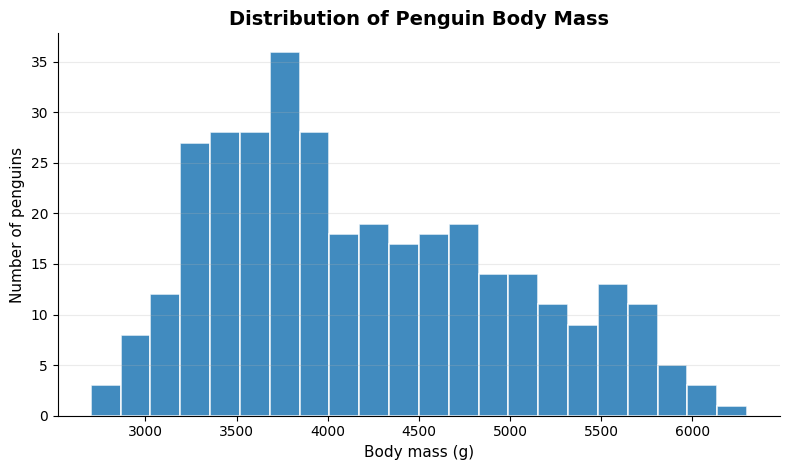

In [34]:
plt.figure(figsize=(8, 4.8))

plt.hist(
    df["body_mass_g"].dropna(),
    bins=22,
    edgecolor="white",
    linewidth=1.2,
    alpha=0.85
)

plt.title("Distribution of Penguin Body Mass", fontsize=14, fontweight="bold")
plt.xlabel("Body mass (g)", fontsize=11)
plt.ylabel("Number of penguins", fontsize=11)

plt.grid(axis="y", alpha=0.25)
plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

The histogram does not look like one single smooth hump. It already shows signs of hidden groups, probably because different species and sexes have different body mass ranges.

# 02_univariate_analysis

## Exercise 1

In [37]:
overall_bill = df["bill_length_mm"].agg(["mean", "median", "std"])
species_bill = df.groupby("species")["bill_length_mm"].agg(["mean", "median", "std"])

print("Overall bill_length_mm:")
display(overall_bill)

print("Bill_length_mm within each species:")
display(species_bill)

Overall bill_length_mm:


mean      43.921930
median    44.450000
std        5.459584
Name: bill_length_mm, dtype: float64

Bill_length_mm within each species:


,mean,median,std
species,,,
Adelie,38.791391,38.80,2.663405
Chinstrap,48.833824,49.55,3.339256
Gentoo,47.504878,47.30,3.081857


The overall standard deviation of bill_length_mm is larger than the standard deviations within each species. This happens because the overall spread mixes together different species, whose bill lengths have different centers. Once the data is split by species, some of the between-species variation is removed, so the spread inside each group becomes smaller. This previews the lesson of Notebook 3: group structure can hide inside an overall distribution.

## Exercise 2

Mean body_mass_g: 4201.754385964912
Median body_mass_g: 4050.0


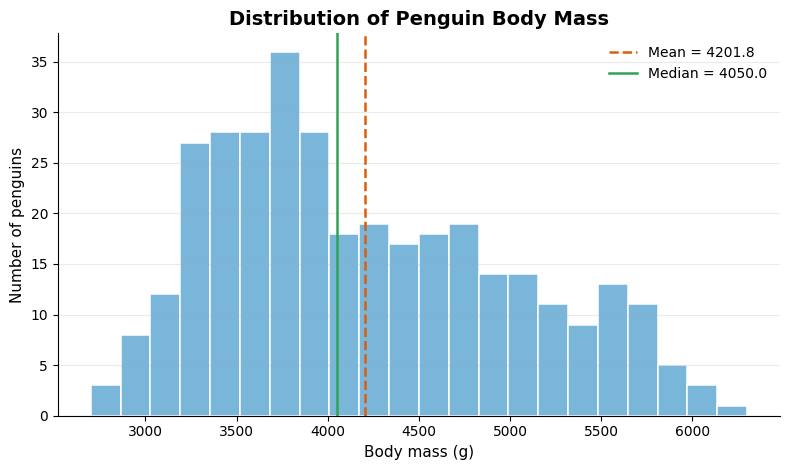

In [48]:
mean_mass = df["body_mass_g"].mean()
median_mass = df["body_mass_g"].median()

print("Mean body_mass_g:", mean_mass)
print("Median body_mass_g:", median_mass)

plt.figure(figsize=(8, 4.8))
sns.histplot(
    data=df,
    x="body_mass_g",
    bins=22,
    kde=False,
    color="#6BAED6",
    edgecolor="white",
    linewidth=1.1,
    alpha=0.9
)

plt.axvline(mean_mass, color="#D95F0E", linestyle="--", linewidth=1.8, label=f"Mean = {mean_mass:.1f}")
plt.axvline(median_mass, color="#31A354", linestyle="-", linewidth=1.8, label=f"Median = {median_mass:.1f}")

plt.title("Distribution of Penguin Body Mass", fontsize=14, fontweight="bold")
plt.xlabel("Body mass (g)", fontsize=11)
plt.ylabel("Number of penguins", fontsize=11)
plt.legend(frameon=False)
plt.grid(axis="y", alpha=0.25)
plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)
plt.tight_layout()
plt.show()

The distribution of body_mass_g is slightly right-skewed because the mean is higher than the median. I would report the median as the typical penguin body mass because it is less affected by heavier penguins and gives a more robust center for a skewed distribution.

## Exercise 3

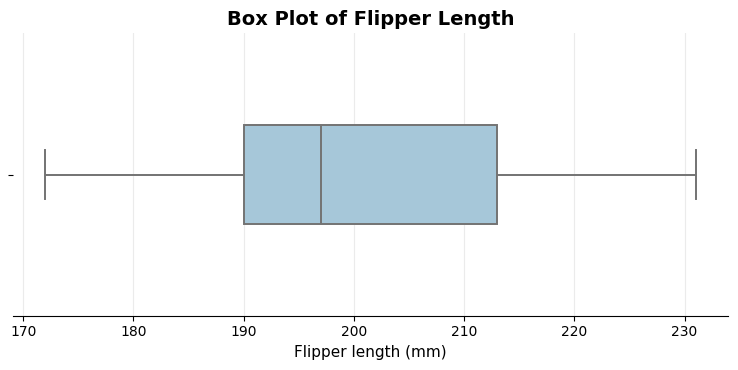

Number of outliers: 0


Series([], Name: flipper_length_mm, dtype: float64)

In [49]:
def find_outliers(x):
    q1 = x.quantile(0.25)
    q3 = x.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    return x[(x < lower) | (x > upper)]

plt.figure(figsize=(7.5, 3.8))
sns.boxplot(
    data=df,
    x="flipper_length_mm",
    color="#9ECAE1",
    width=0.35,
    linewidth=1.4,
    fliersize=4
)

plt.title("Box Plot of Flipper Length", fontsize=14, fontweight="bold")
plt.xlabel("Flipper length (mm)", fontsize=11)
plt.grid(axis="x", alpha=0.25)
plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)
plt.gca().spines["left"].set_visible(False)
plt.tight_layout()
plt.show()

outliers_flipper = find_outliers(df["flipper_length_mm"].dropna())
print("Number of outliers:", len(outliers_flipper))
display(outliers_flipper)

The 1.5 × IQR rule flags about zero outliers for flipper_length_mm, even though the distribution is bimodal. This is not a contradiction: the two humps are still within the overall non-outlier range, so the rule does not treat either group as extreme. The lesson is that outlier rules can detect extreme values, but they cannot detect hidden subgroups or multimodal structure.

## Exercise 4

,count,proportion
island,,
Biscoe,168,0.488372
Dream,124,0.360465
Torgersen,52,0.151163


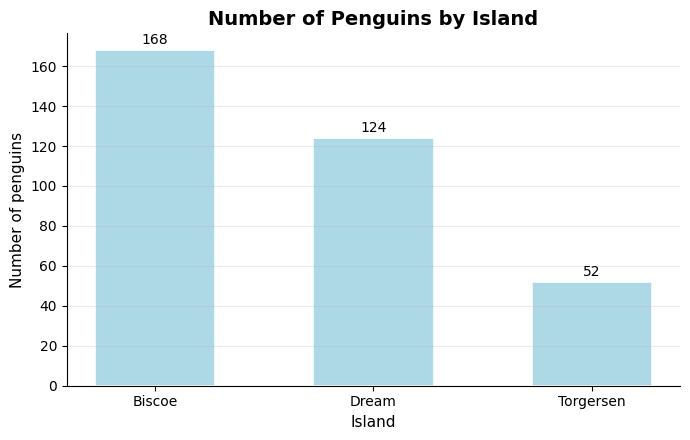

Island with the most penguins: Biscoe


In [51]:
# 4. Bar chart of island

island_counts = df["island"].value_counts()
island_props = df["island"].value_counts(normalize=True)

island_summary = pd.DataFrame({
    "count": island_counts,
    "proportion": island_props
})

display(island_summary)

plt.figure(figsize=(7, 4.5))
plt.bar(
    island_counts.index,
    island_counts.values,
    width=0.55,
    color="lightblue",
    edgecolor="white",
    linewidth=1.2
)

plt.title("Number of Penguins by Island", fontsize=14, fontweight="bold")
plt.xlabel("Island", fontsize=11)
plt.ylabel("Number of penguins", fontsize=11)
plt.grid(axis="y", alpha=0.25)
plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)

for i, value in enumerate(island_counts.values):
    plt.text(i, value + 3, str(value), ha="center", fontsize=10)

plt.tight_layout()
plt.show()

print("Island with the most penguins:", island_counts.idxmax())

Biscoe hosts the most penguins. The island proportions show that penguins are not evenly distributed across islands.

## Exercise 5

In [45]:
numeric_cols = df.select_dtypes(include="number").columns
cv = df[numeric_cols].std() / df[numeric_cols].mean()

cv_summary = pd.DataFrame({
    "mean": df[numeric_cols].mean(),
    "std": df[numeric_cols].std(),
    "coefficient_of_variation": cv
}).sort_values("coefficient_of_variation", ascending=False)

display(cv_summary)

print("Largest relative variation:", cv_summary.index[0])

,mean,std,coefficient_of_variation
body_mass_g,4201.754386,801.954536,0.190862
bill_length_mm,43.921930,5.459584,0.124302
bill_depth_mm,17.151170,1.974793,0.115140
flipper_length_mm,200.915205,14.061714,0.069988


Largest relative variation: body_mass_g


The measurement with the largest coefficient of variation varies the most relative to its own size. This is fairer than comparing raw standard deviations because the numeric columns are measured on different scales; for example, body mass is measured in thousands of grams, while bill measurements are only in tens of millimeters.

## Exercise 6

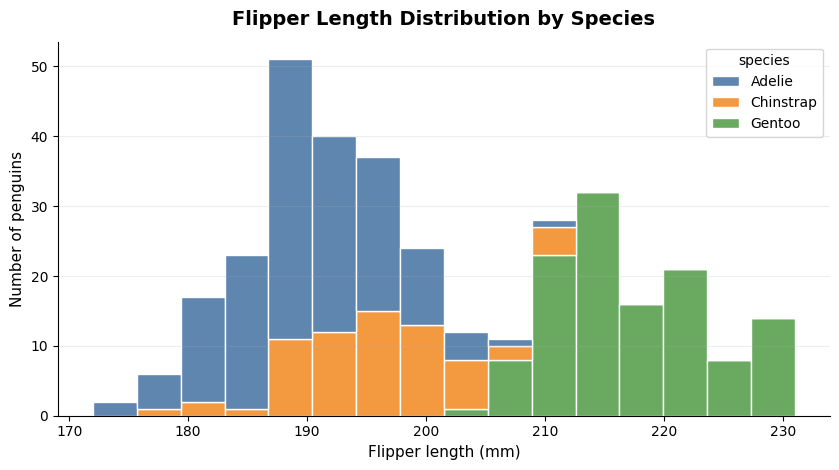

In [55]:
# 6. Flipper-length histogram by species

plt.figure(figsize=(8.5, 4.8))

sns.histplot(
    data=df,
    x="flipper_length_mm",
    hue="species",
    bins=16,
    multiple="stack",
    kde=False,
    edgecolor="white",
    linewidth=1,
    alpha=0.9,
    palette={
        "Adelie": "#4E79A7",
        "Chinstrap": "#F28E2B",
        "Gentoo": "#59A14F"
    }
)

plt.title("Flipper Length Distribution by Species", fontsize=14, fontweight="bold", pad=12)
plt.xlabel("Flipper length (mm)", fontsize=11)
plt.ylabel("Number of penguins", fontsize=11)
plt.grid(axis="y", alpha=0.22)
plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)
plt.tight_layout()
plt.show()

The stacked colours show that Gentoo penguins dominate the longer-flipper range, while Adelie and Chinstrap mainly appear in the shorter-flipper range with some overlap. The two humps are therefore mostly explained by species differences, especially Gentoo being separated from the other two species.

# 03_bivariate_analysis

## Exercise 1

In [88]:
palette = {"Adelie": "#4E79A7", "Chinstrap": "#F28E2B", "Gentoo": "#59A14F"}
species_mass = df.groupby("species")["body_mass_g"].agg(["mean", "std"])
display(species_mass)

,mean,std
species,,
Adelie,3700.662252,458.566126
Chinstrap,3733.088235,384.335081
Gentoo,5076.016260,504.116237


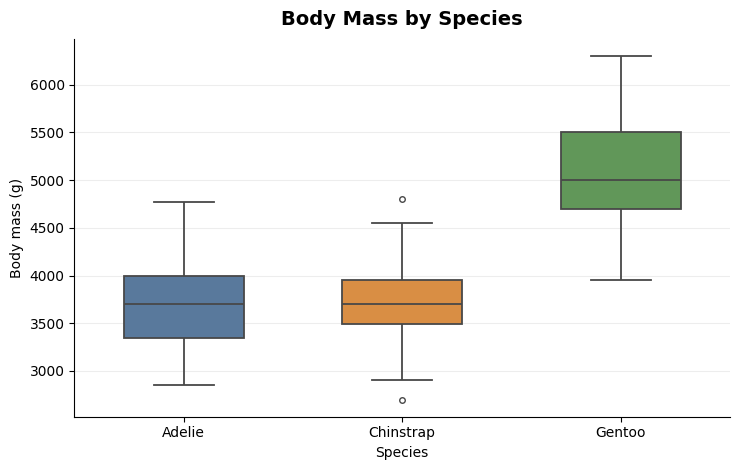

In [90]:
plt.figure(figsize=(7.5, 4.8))
sns.boxplot(data=df, x="species", y="body_mass_g", hue="species", palette=palette, width=0.55, linewidth=1.3, fliersize=4, legend=False)
plt.title("Body Mass by Species", fontsize=14, fontweight="bold", pad=10)
plt.xlabel("Species"); plt.ylabel("Body mass (g)")
plt.grid(axis="y", alpha=0.22)
plt.gca().spines["top"].set_visible(False); plt.gca().spines["right"].set_visible(False)
plt.tight_layout(); plt.show()

Gentoo penguins have the highest mean body mass, so they are the heaviest on average. However, the box plot shows that the species still overlap. If a penguin weighs 4500 g, I could not confidently name its species from weight alone, because that value can fall near the overlap between groups. Comparing means alone ignores the spread within each species.

## Exercise 2

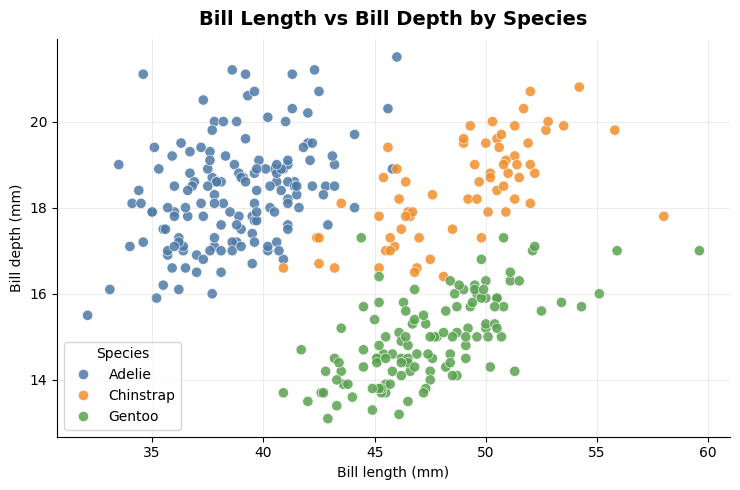

In [78]:
plt.figure(figsize=(7.5, 5))
sns.scatterplot(data=df, x="bill_length_mm", y="bill_depth_mm", hue="species", palette=palette, s=55, alpha=0.85, edgecolor="white", linewidth=0.5)
plt.title("Bill Length vs Bill Depth by Species", fontsize=14, fontweight="bold", pad=10)
plt.xlabel("Bill length (mm)"); plt.ylabel("Bill depth (mm)")
plt.grid(alpha=0.22)
plt.gca().spines["top"].set_visible(False); plt.gca().spines["right"].set_visible(False)
plt.legend(title="Species", frameon=True)
plt.tight_layout(); plt.show()

The colours reveal three species-level clusters. Adelie penguins mostly have shorter bills and relatively deeper bills, Chinstrap penguins tend to have longer and deeper bills, while Gentoo penguins have longer but shallower bills. A plain scatter plot would hide that the apparent relationship is strongly shaped by species groups.

## Exercise 3

In [61]:
species_island_pct = pd.crosstab(df["species"], df["island"], normalize="index") * 100
display(species_island_pct.round(2))

species_island_count = pd.crosstab(df["species"], df["island"])
display(species_island_count)

only_one_species_islands = species_island_count.astype(bool).sum(axis=0)
print("Islands with only one species:")
print(only_one_species_islands[only_one_species_islands == 1].index.tolist())

island,Biscoe,Dream,Torgersen
species,,,
Adelie,28.95,36.84,34.21
Chinstrap,0.00,100.00,0.00
Gentoo,100.00,0.00,0.00


island,Biscoe,Dream,Torgersen
species,,,
Adelie,44,56,52
Chinstrap,0,68,0
Gentoo,124,0,0


Islands with only one species:
['Torgersen']


Dream island contains Adelie and Chinstrap, Biscoe contains Adelie and Gentoo, and Torgersen contains only Adelie. Therefore, Torgersen is the island home to only one species in this dataset.

## Exercise 4

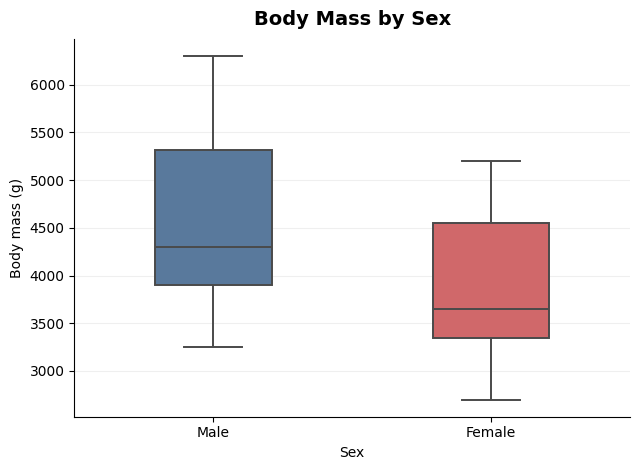

,mean,median,std,count
sex,,,,
Female,3862.272727,3650.0,666.172050,165
Male,4545.684524,4300.0,787.628884,168


In [79]:
plt.figure(figsize=(6.5, 4.8))

sns.boxplot(
    data=df,
    x="sex",
    y="body_mass_g",
    hue="sex",
    palette={
        "Male": "#4E79A7",
        "Female": "#E15759"
    },
    width=0.42,
    linewidth=1.4,
    fliersize=4,
    legend=False
)

plt.title("Body Mass by Sex", fontsize=14, fontweight="bold", pad=10)
plt.xlabel("Sex")
plt.ylabel("Body mass (g)")
plt.grid(axis="y", alpha=0.2)
plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)
plt.tight_layout()
plt.show()

display(df.groupby("sex")["body_mass_g"].agg(["mean", "median", "std", "count"]))

Males tend to be heavier than females. Both the mean and median body mass are higher for males, and the male box is positioned higher overall.

## Exercise 5

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
bill_length_mm,1.000000,-0.235053,0.656181,0.595110
bill_depth_mm,-0.235053,1.000000,-0.583851,-0.471916
flipper_length_mm,0.656181,-0.583851,1.000000,0.871202
body_mass_g,0.595110,-0.471916,0.871202,1.000000


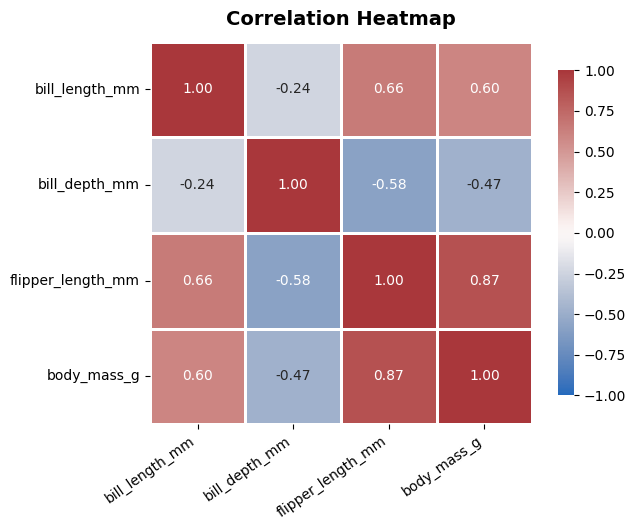

In [81]:
numeric_df = df.select_dtypes(include="number")
corr = numeric_df.corr()
display(corr)

plt.figure(figsize=(6.8, 5.4))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1,
            linewidths=1, linecolor="white", square=True, cbar_kws={"shrink": 0.85})

plt.title("Correlation Heatmap", fontsize=14, fontweight="bold", pad=12)
plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [83]:
mask = np.triu(np.ones_like(corr, dtype=bool))
corr_pairs = corr.mask(mask).abs().stack()
strongest_pair = corr_pairs.idxmax()

print("Strongest relationship:", strongest_pair)
print("Correlation value:", corr.loc[strongest_pair[0], strongest_pair[1]])

Strongest relationship: ('body_mass_g', 'flipper_length_mm')
Correlation value: 0.871201767306011


In [84]:
within_species_corr = df.groupby("species").apply(
    lambda g: g["bill_length_mm"].corr(g["bill_depth_mm"])
)

print("\nWithin-species correlations between bill_length_mm and bill_depth_mm:")
print(within_species_corr)


Within-species correlations between bill_length_mm and bill_depth_mm:
species
Adelie       0.391492
Chinstrap    0.653536
Gentoo       0.643384
dtype: float64


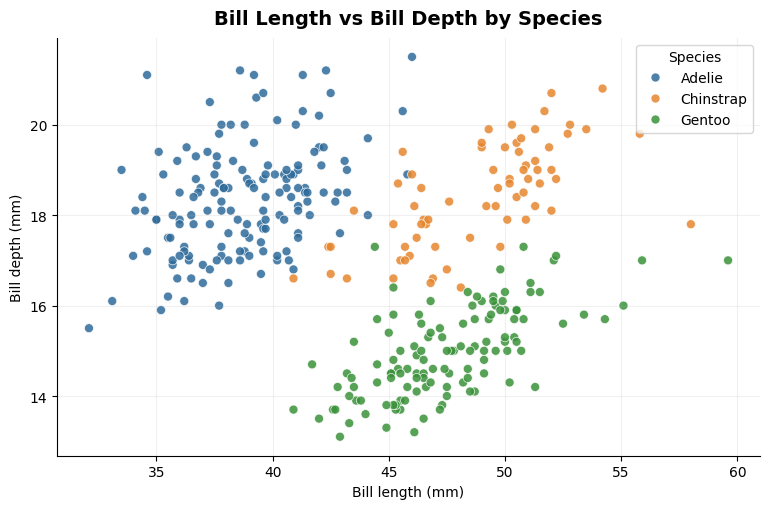

In [85]:
plt.figure(figsize=(7.8, 5.2))

sns.scatterplot(
    data=df,
    x="bill_length_mm",
    y="bill_depth_mm",
    hue="species",
    palette={"Adelie": "#2F6B9A", "Chinstrap": "#E6862E", "Gentoo": "#3A923A"},
    s=42,
    alpha=0.85
)

plt.title("Bill Length vs Bill Depth by Species", fontsize=14, fontweight="bold", pad=10)
plt.xlabel("Bill length (mm)")
plt.ylabel("Bill depth (mm)")
plt.grid(alpha=0.18)
plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)
plt.legend(title="Species", frameon=True)
plt.tight_layout()
plt.show()

The strongest relationship is between body_mass_g and flipper_length_mm, with a correlation of about 0.87. The heatmap shows a weak negative correlation between bill_length_mm and bill_depth_mm overall, but the coloured scatter plot shows that this single number is misleading. Within species, the relationship is not the same as the pooled pattern: the negative overall correlation is largely created by mixing species with different bill shapes. This connects to Simpson's paradox, where the overall trend can differ from the trends inside groups.

## Exercise 6

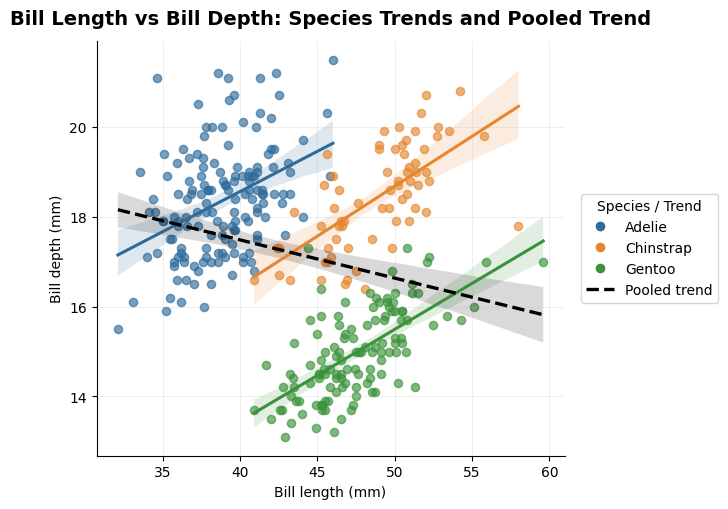

In [87]:
g = sns.lmplot(data=df, x="bill_length_mm", y="bill_depth_mm", hue="species", palette={"Adelie": "#2F6B9A", "Chinstrap": "#E6862E", "Gentoo": "#3A923A"}, height=5.2, aspect=1.35, legend=False, scatter_kws={"s": 35, "alpha": 0.65}, line_kws={"linewidth": 2.2})

ax = g.ax
sns.regplot(data=df, x="bill_length_mm", y="bill_depth_mm", scatter=False, ax=ax, color="black", line_kws={"linewidth": 2.4, "linestyle": "--"})

ax.set_title("Bill Length vs Bill Depth: Species Trends and Pooled Trend", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Bill length (mm)")
ax.set_ylabel("Bill depth (mm)")
ax.grid(alpha=0.18)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

from matplotlib.lines import Line2D
legend_items = [
    Line2D([0], [0], marker="o", color="w", label="Adelie", markerfacecolor="#2F6B9A", markersize=8),
    Line2D([0], [0], marker="o", color="w", label="Chinstrap", markerfacecolor="#E6862E", markersize=8),
    Line2D([0], [0], marker="o", color="w", label="Gentoo", markerfacecolor="#3A923A", markersize=8),
    Line2D([0], [0], color="black", linestyle="--", linewidth=2.4, label="Pooled trend")
]
ax.legend(handles=legend_items, title="Species / Trend", loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=True)

plt.tight_layout()
plt.show()

The pooled line slopes downward, while the per-species lines generally slope upward within each species. This shows the Simpson's paradox pattern clearly: the overall negative relationship appears after combining species, but it does not honestly represent the within-species relationships.

# 04_hypothesis_driven_eda

In [91]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing

cal = fetch_california_housing()
homes = pd.DataFrame(cal.data, columns=cal.feature_names)
homes["MedHouseVal"] = cal.target

homes.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


## Exercise 1

In [92]:
ratio = homes.max(numeric_only=True) / homes.median(numeric_only=True)
ratio_summary = pd.DataFrame({"median": homes.median(numeric_only=True), "max": homes.max(numeric_only=True), "max_over_median": ratio}).sort_values("max_over_median", ascending=False)

display(ratio_summary)
print("Most suspicious column:", ratio_summary.index[0])

,median,max,max_over_median
AveOccup,2.818116,1243.333333,441.193154
AveBedrms,1.048780,34.066667,32.482171
Population,1166.000000,35682.000000,30.602058
AveRooms,5.229129,141.909091,27.138190
MedInc,3.534800,15.000100,4.243550
MedHouseVal,1.797000,5.000010,2.782421
HouseAge,29.000000,52.000000,1.793103
Latitude,34.260000,41.950000,1.224460
Longitude,-118.490000,-114.310000,0.964723


Most suspicious column: AveOccup


The most suspicious column is AveOccup. Its maximum is 1243.33, while its median is only about 2.82, giving a max-to-median ratio of about 441. This suggests that the column contains an extreme and possibly impossible outlier. This connects to Section 5 because data-quality issues can be hidden inside numeric columns and may distort plots, summary statistics, and later models.

## Exercise 2

Correlation between HouseAge and MedHouseVal: 0.1056234124932099


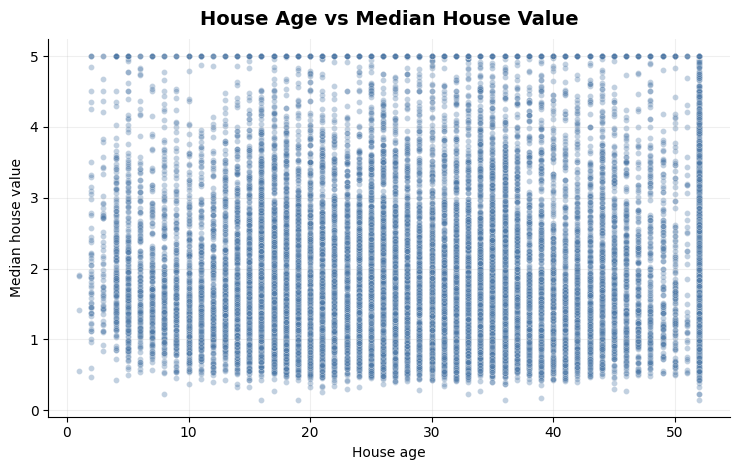

In [99]:
corr_age_value = homes["HouseAge"].corr(homes["MedHouseVal"])
print("Correlation between HouseAge and MedHouseVal:", corr_age_value)

plt.figure(figsize=(7.5, 4.8))
sns.scatterplot(data=homes, x="HouseAge", y="MedHouseVal", s=18, alpha=0.35, color="#4E79A7")
plt.title("House Age vs Median House Value", fontsize=14, fontweight="bold", pad=10)
plt.xlabel("House age")
plt.ylabel("Median house value")
plt.grid(alpha=0.2)
plt.gca().spines["top"].set_visible(False); plt.gca().spines["right"].set_visible(False)
plt.tight_layout(); plt.show()

The correlation between HouseAge and MedHouseVal is about 0.106, which is very weak and slightly positive. The scatter plot also does not show a clear downward pattern. Therefore, the hypothesis that older houses are cheaper is not supported; the relationship between house age and median house value is weak or almost absent.

## Exercise 3

crowded
False    2.037
True     1.585
Name: MedHouseVal, dtype: float64

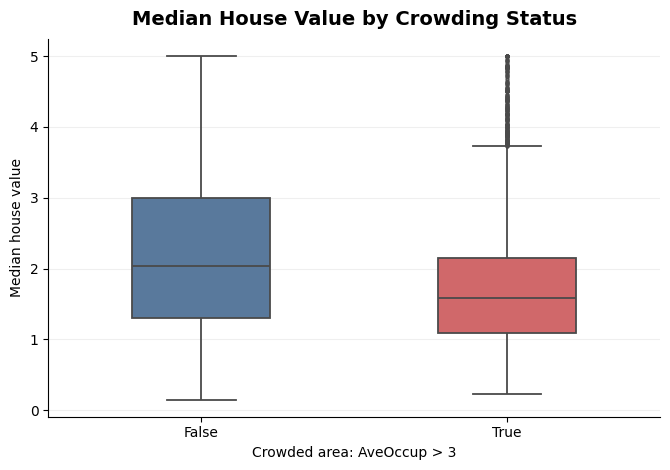

In [94]:
homes["crowded"] = homes["AveOccup"] > 3
crowded_medians = homes.groupby("crowded")["MedHouseVal"].median()
display(crowded_medians)

plt.figure(figsize=(6.8, 4.8))
sns.boxplot(data=homes, x="crowded", y="MedHouseVal", hue="crowded", palette={False: "#4E79A7", True: "#E15759"}, width=0.45, linewidth=1.3, fliersize=2, legend=False)
plt.title("Median House Value by Crowding Status", fontsize=14, fontweight="bold", pad=10)
plt.xlabel("Crowded area: AveOccup > 3")
plt.ylabel("Median house value")
plt.grid(axis="y", alpha=0.2)
plt.gca().spines["top"].set_visible(False); plt.gca().spines["right"].set_visible(False)
plt.tight_layout(); plt.show()

The median house value is lower in crowded areas. The median is about 2.037 for non-crowded neighbourhoods and about 1.585 for crowded neighbourhoods. This supports the hypothesis that crowded areas differ in price, and in this dataset they tend to have lower median house values. However, both groups still have wide variation and many high-value observations, so crowding alone does not fully explain house value.

## Exercise 4

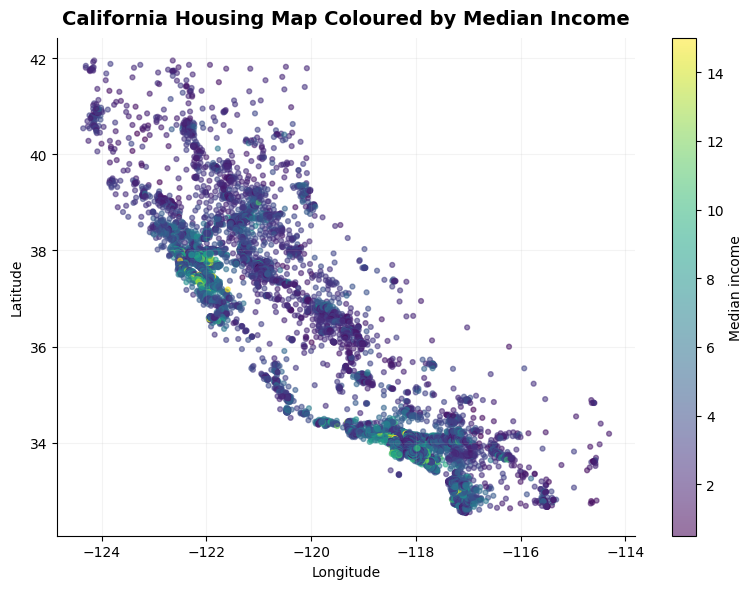

In [95]:
plt.figure(figsize=(8, 6))
sc = plt.scatter(homes["Longitude"], homes["Latitude"], c=homes["MedInc"], cmap="viridis", s=12, alpha=0.55)
plt.colorbar(sc, label="Median income")
plt.title("California Housing Map Coloured by Median Income", fontsize=14, fontweight="bold", pad=10)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.grid(alpha=0.15)
plt.gca().spines["top"].set_visible(False); plt.gca().spines["right"].set_visible(False)
plt.tight_layout(); plt.show()

The income map shows a spatial pattern similar to the value map: higher-income neighbourhoods are concentrated along the coast and around major urban areas, while many inland areas have lower income. This similarity suggests that the geographic pattern of house values is partly explained by the geographic distribution of income.

## Exercise 5

In [96]:
cap_value = homes["MedHouseVal"].max()
cap_count = (homes["MedHouseVal"] == cap_value).sum()
cap_pct = cap_count / len(homes) * 100

print("Cap value:", cap_value)
print("Number of capped neighbourhoods:", cap_count)
print("Percentage at cap:", cap_pct)

Cap value: 5.00001
Number of capped neighbourhoods: 965
Percentage at cap: 4.675387596899225


About 4.68% of neighbourhoods sit exactly at the value cap of 5.00001, or about $500k. This percentage matters for a price-prediction model because capped values are not true market prices. They hide the real variation above the cap, so a model trained on this target may underestimate expensive neighbourhoods and learn a distorted upper end of the price distribution.

## Exercise 6

Correlation between MedInc and MedHouseVal: 0.6880752079585478


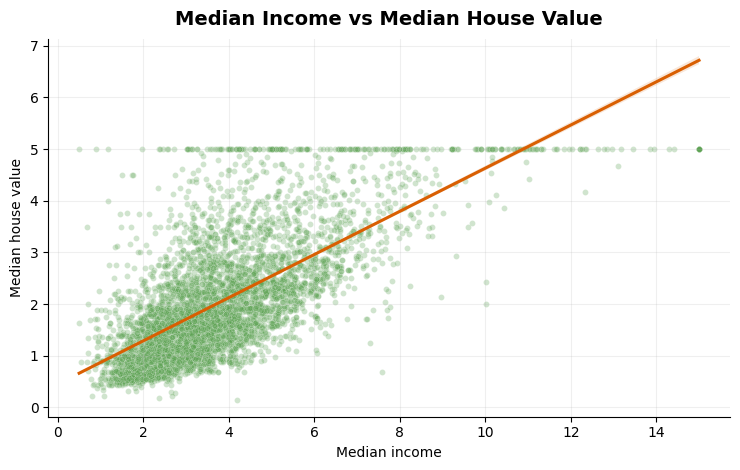

In [100]:
hyp_corr = homes["MedInc"].corr(homes["MedHouseVal"])
print("Correlation between MedInc and MedHouseVal:", hyp_corr)

plot_data = homes.sample(5000, random_state=42)

plt.figure(figsize=(7.5, 4.8))
sns.scatterplot(data=plot_data, x="MedInc", y="MedHouseVal", s=18, alpha=0.28, color="#59A14F")
sns.regplot(data=homes, x="MedInc", y="MedHouseVal", scatter=False, color="#D95F02", line_kws={"linewidth": 2.2})
plt.title("Median Income vs Median House Value", fontsize=14, fontweight="bold", pad=10)
plt.xlabel("Median income"); plt.ylabel("Median house value")
plt.grid(alpha=0.2)
plt.gca().spines["top"].set_visible(False); plt.gca().spines["right"].set_visible(False)
plt.tight_layout(); plt.show()

Hypothesis: Neighbourhoods with higher median income tend to have higher median house values.

Supporting number: The correlation between MedInc and MedHouseVal is about 0.688, which indicates a fairly strong positive relationship.

Verdict: The hypothesis is supported. The scatter plot shows that house value generally increases as median income increases.

Caveat: The relationship is affected by the $500k value cap, visible as a horizontal band at the top of the plot. This cap compresses the upper end of house values, so the true relationship between income and value may be stronger or more complex than the plot shows.